In [1]:
import pandas as pd
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [3]:
rng = np.random.default_rng(73512)

# Dane syntetyczne

In [4]:
indices = np.arange(0, 50, 0.02)
synthetic_data = (np.sin(indices * 3) + indices / 10 + (indices / 10) ** 2 + np.sin(indices * 10)) #/ np.exp(indices / 20)
print(synthetic_data)
synthetic_data.shape

[ 0.          0.26063734  0.51314655 ... 29.21851287 29.0759124
 28.93963031]


(2500,)

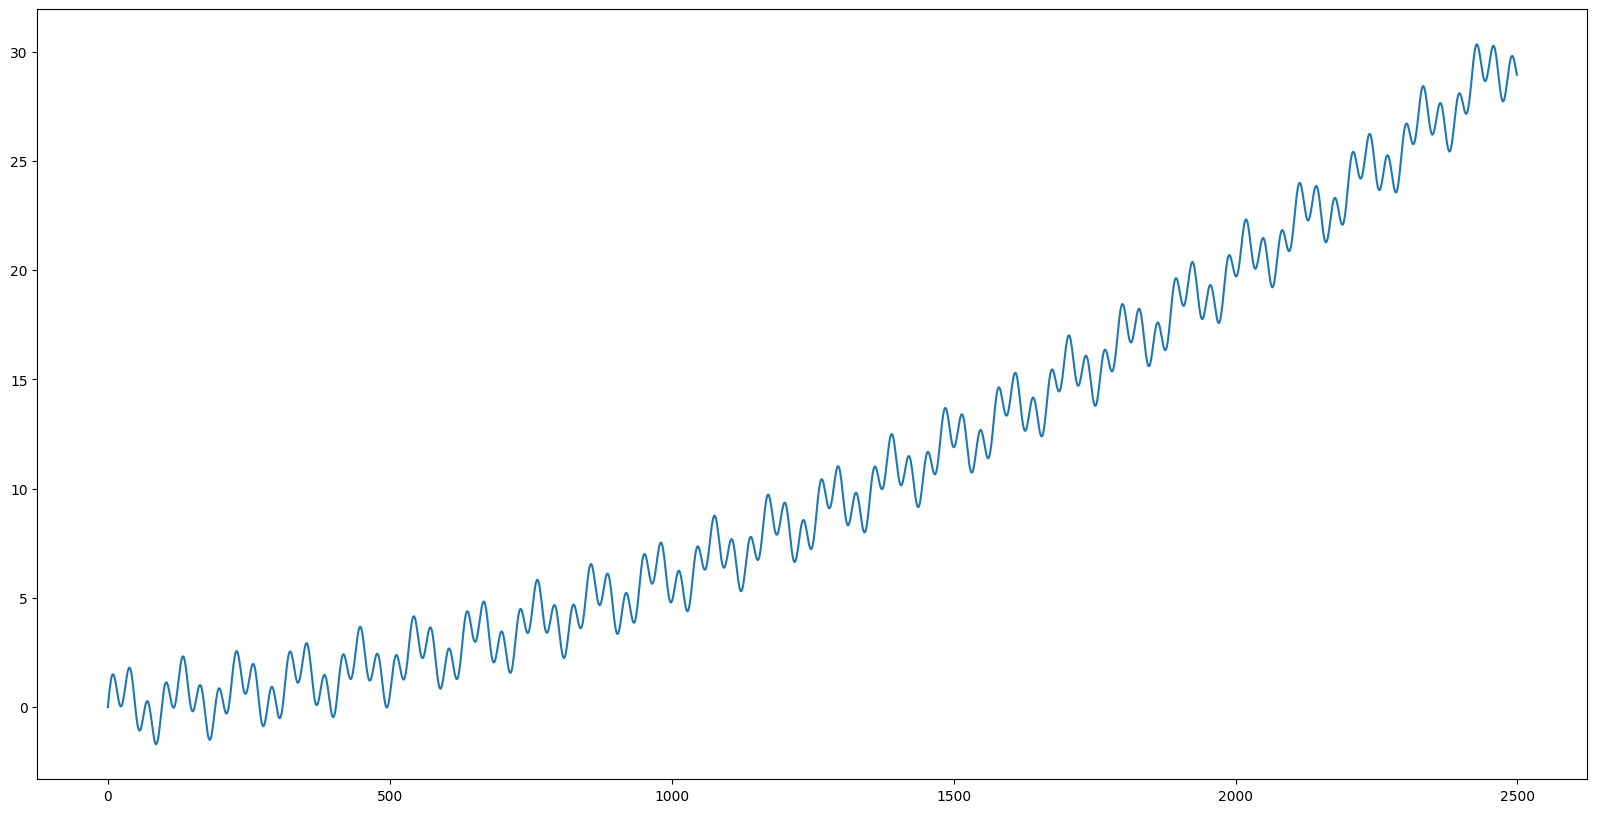

In [5]:
plt.figure(figsize=[20, 10])
plt.plot(synthetic_data)
plt.show()

In [6]:
min_value = synthetic_data.min()
max_value = synthetic_data.max()

In [7]:
data_seq = []
data_targets = []
sequence_len = 150
for i in range(len(synthetic_data) - sequence_len - 1):
    data_seq.append(torch.from_numpy(synthetic_data[i:i + sequence_len]))
    data_targets.append(synthetic_data[i + sequence_len + 1])

len(data_seq)

2349

In [8]:
data = (torch.stack(data_seq).float() - min_value) / max_value
data_targets = (torch.Tensor(data_targets).float() - min_value) / max_value
train_indices = rng.random(len(data_seq)) > 0.3
print(train_indices) 
test_indices = ~train_indices   # bitwise negation
print(test_indices)
train_set = torch.utils.data.TensorDataset(data[train_indices], data_targets[train_indices])
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
test_data, test_targets = data[test_indices], data_targets[test_indices]

[ True  True  True ... False  True False]
[False False False ...  True False  True]


In [9]:
class SimpleRegressor(nn.Module):

    def __init__(self, num_inputs, num_hidden, num_outputs):
        super().__init__()
        self.linear1 = nn.Linear(num_inputs, num_hidden)
        self.act_fn = nn.Tanh()
        self.linear2 = nn.Linear(num_hidden, num_outputs)

    def forward(self, x):
        x = self.linear1(x)
        x = self.act_fn(x)
        x = self.linear2(x)
        return x
    
model = SimpleRegressor(sequence_len, 5, 1).to(device)
model

SimpleRegressor(
  (linear1): Linear(in_features=150, out_features=5, bias=True)
  (act_fn): Tanh()
  (linear2): Linear(in_features=5, out_features=1, bias=True)
)

In [10]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fun = nn.MSELoss()

In [11]:
model.train() 

# Training loop
for epoch in range(101):
    for x, targets in train_loader:
        x = x.to(device)
        targets = targets.to(device)

        preds = model(x)
        preds = preds.squeeze(dim=1) 
        
        optimizer.zero_grad() 
        loss = loss_fun(preds, targets)
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

Epoch: 0, loss: 0.0361
Epoch: 10, loss: 0.00669
Epoch: 20, loss: 0.00135
Epoch: 30, loss: 0.000816
Epoch: 40, loss: 0.000965
Epoch: 50, loss: 0.000736
Epoch: 60, loss: 0.00012
Epoch: 70, loss: 0.000109
Epoch: 80, loss: 6.44e-05
Epoch: 90, loss: 1.32e-05
Epoch: 100, loss: 7.52e-05


In [12]:
with torch.no_grad():
    test_preds = model(test_data.to(device))
    print(torch.abs(test_preds.squeeze()-test_targets.to(device)).mean())   # MAE - mean absolute error

tensor(0.0089, device='mps:0')


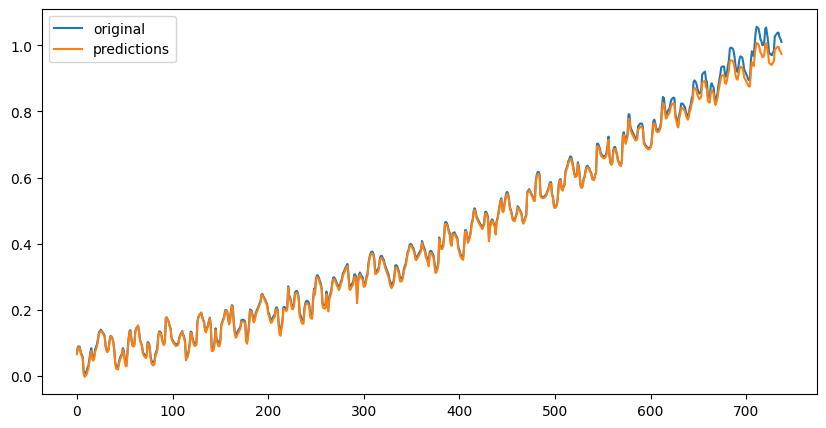

In [13]:
plt.figure(figsize=[10, 5])
plt.plot(test_targets.numpy(), label='original')
plt.plot(test_preds.cpu().numpy(), label='predictions')
plt.legend()
plt.show()

## Koniec laborki?

### Co poszło nie tak?

In [14]:
train_split = int(len(data) * 0.7)
train_set = torch.utils.data.TensorDataset(data[:train_split], data_targets[:train_split])
train_loader = DataLoader(train_set, batch_size=32, drop_last=True)
test_data, test_targets = data[train_split:], data_targets[train_split:]

In [15]:
model = SimpleRegressor(sequence_len, 5, 1).to(device)
model
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fun = nn.MSELoss()

# Training loop
for epoch in range(101):
    for x, targets in train_loader:
        x = x.to(device)
        targets = targets.to(device)

        preds = model(x)
        preds = preds.squeeze(dim=1) 
        
        optimizer.zero_grad() 
        loss = loss_fun(preds, targets)
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

Epoch: 0, loss: 0.00059
Epoch: 10, loss: 0.000128
Epoch: 20, loss: 0.000222
Epoch: 30, loss: 0.000221
Epoch: 40, loss: 0.00021
Epoch: 50, loss: 0.000234
Epoch: 60, loss: 0.000246
Epoch: 70, loss: 0.000256
Epoch: 80, loss: 0.000262
Epoch: 90, loss: 0.00027
Epoch: 100, loss: 0.000271


In [16]:
with torch.no_grad():
    test_preds = model(test_data.to(device))
    print(torch.abs(test_preds.squeeze() - test_targets.to(device)).mean())

tensor(0.1704, device='mps:0')


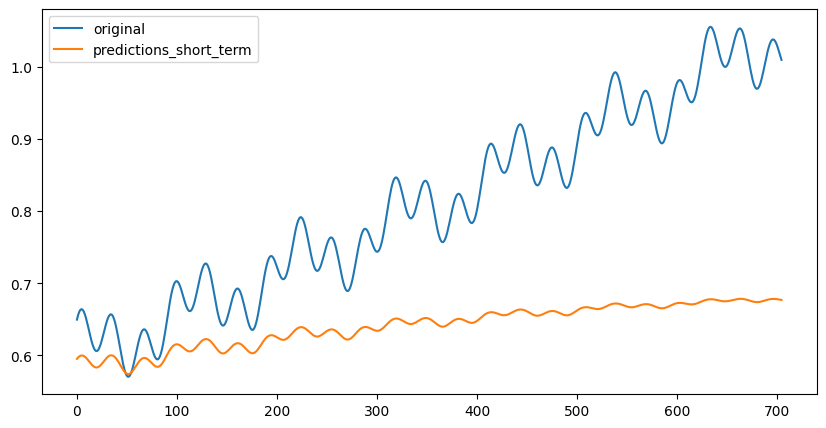

In [17]:
plt.figure(figsize=[10, 5])
plt.plot(test_targets.numpy(), label='original')
plt.plot(test_preds.cpu().numpy(), label='predictions_short_term')
plt.legend()
plt.show()

# Sieć rekurencyjna

In [18]:
class RecurrentRegressor(nn.Module):

    def __init__(self, num_inputs, num_hidden, num_outputs, num_state):
        super().__init__()
        self.linear1 = nn.Linear(num_inputs + num_state, num_hidden)
        self.act_fn = nn.Tanh()
        self.linear_out = nn.Linear(num_hidden, num_outputs)
        self.linear_state = nn.Linear(num_hidden, num_state)

    def forward(self, x, state):
        x = torch.cat([x, state], 1)
        x = self.linear1(x)
        x = self.act_fn(x)
        out = self.linear_out(x)
        state = self.linear_state(x)
        return out, state
    
model = RecurrentRegressor(1, 5, 1, 5).to(device)
model

RecurrentRegressor(
  (linear1): Linear(in_features=6, out_features=5, bias=True)
  (act_fn): Tanh()
  (linear_out): Linear(in_features=5, out_features=1, bias=True)
  (linear_state): Linear(in_features=5, out_features=5, bias=True)
)

### Dokończ pętlę uczącą poniżej:

In [20]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fun = nn.MSELoss()

for epoch in range(101):
    for x, targets in train_loader:
        x = x.to(device)
        targets = targets.to(device)
        loss_total = 0
        state = torch.zeros(len(x), 5).to(device)
        optimizer.zero_grad() 
        for i in range(x.size(1)):  # x.size(1) = 150
            x_one = x[:,i].unsqueeze(1) 
            if i < sequence_len - 1:
                target = x[:,i+1]
            else:
                target = targets
            preds, state = model(x_one, state)
            preds = preds.squeeze(dim=1) 
            loss = loss_fun(preds, target)
            loss_total += loss
        loss_total.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

Epoch: 0, loss: 0.06
Epoch: 10, loss: 0.00187
Epoch: 20, loss: 0.00106
Epoch: 30, loss: 0.00067
Epoch: 40, loss: 0.000451
Epoch: 50, loss: 0.000325
Epoch: 60, loss: 0.000237
Epoch: 70, loss: 0.00016
Epoch: 80, loss: 0.000108
Epoch: 90, loss: 9.4e-05
Epoch: 100, loss: 9.8e-05


In [21]:
with torch.no_grad():
    state = torch.zeros(len(test_data), 5).to(device)
    test_preds = []
    for i in range(test_data.size(1)):
        x_one = test_data[:, i].unsqueeze(1).to(device)
        preds, state = model(x_one, state)
    test_preds.append(preds)
    print(torch.abs((torch.cat(test_preds).squeeze() - test_targets.to(device))).mean())

tensor(0.0588, device='mps:0')


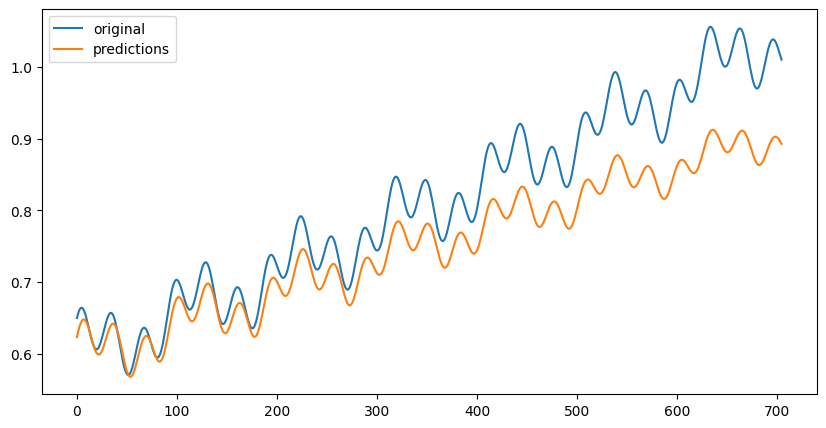

In [22]:
plt.figure(figsize=[10, 5])
plt.plot(test_targets, label='original')
plt.plot(torch.cat(test_preds).squeeze().cpu().numpy(), label='predictions')
plt.legend()
plt.show()

# Sieci rekurencyjne w Torchu

In [23]:
batch_size = 2
input_size = 3
hidden_size = 4
num_layers = 2
rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, num_layers=2, batch_first=False) #batch_first=False is default!!
rnn

RNN(3, 4, num_layers=2)

In [24]:
with torch.no_grad():
    sequence_len = 5
    x = torch.randn(sequence_len, batch_size, input_size)
    h0 = torch.randn(num_layers, batch_size, hidden_size)
    output, hn = rnn(x, h0)
output

tensor([[[ 0.4702,  0.6624,  0.7097, -0.5599],
         [-0.5419,  0.0813, -0.0591,  0.0921]],

        [[ 0.3473,  0.3369,  0.7445, -0.3599],
         [ 0.5613,  0.0048,  0.7675, -0.4008]],

        [[ 0.1105,  0.0417,  0.2430, -0.1798],
         [-0.1773, -0.0451, -0.3010,  0.1459]],

        [[ 0.0970,  0.1095,  0.4869,  0.0517],
         [-0.2325, -0.0491,  0.1455,  0.3874]],

        [[ 0.2671,  0.0858,  0.6621, -0.1768],
         [ 0.3562, -0.0959,  0.8711, -0.0521]]])

In [25]:
output[-1]

tensor([[ 0.2671,  0.0858,  0.6621, -0.1768],
        [ 0.3562, -0.0959,  0.8711, -0.0521]])

In [26]:
hn

tensor([[[ 0.6625,  0.4358, -0.2627, -0.3543],
         [-0.3213,  0.6855, -0.6313,  0.3210]],

        [[ 0.2671,  0.0858,  0.6621, -0.1768],
         [ 0.3562, -0.0959,  0.8711, -0.0521]]])

In [ ]:
class RNNRegressor(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, out_size):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers)
        self.fc = nn.Linear(hidden_size, out_size)
        
    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.num_layers, batch_size, self.hidden_size)
        return hidden
    
    def forward(self, x, hidden):
        x = torch.transpose(x, 0, 1)
        all_outputs, hidden = self.rnn(x, hidden)
        out = all_outputs[-1] # We are interested only in the last output
        x = self.fc(out)
        return x, hidden

 
model = RNNRegressor(1, 5, 2, 1).to(device)
model

RNNRegressor(
  (rnn): RNN(1, 5, num_layers=2)
  (fc): Linear(in_features=5, out_features=1, bias=True)
)

In [28]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fun = nn.MSELoss()

for epoch in range(101):
    for x, targets in train_loader:
        x = x.to(device).unsqueeze(2)
        targets = targets.to(device)
        hidden = model.init_hidden(x.size(0)).to(device)
        preds, last_hidden = model(x, hidden)
        preds = preds.squeeze(1)
        optimizer.zero_grad() 
        loss = loss_fun(preds, targets)
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

Epoch: 0, loss: 0.0596
Epoch: 10, loss: 0.00282
Epoch: 20, loss: 0.00074
Epoch: 30, loss: 0.000506
Epoch: 40, loss: 0.000406
Epoch: 50, loss: 0.000349
Epoch: 60, loss: 0.000277
Epoch: 70, loss: 0.000197
Epoch: 80, loss: 0.000144
Epoch: 90, loss: 0.000112
Epoch: 100, loss: 7.96e-05


In [ ]:
with torch.no_grad():
    hidden = model.init_hidden(len(test_data)).to(device)
    test_preds, _ = model(test_data.to(device).unsqueeze(2),hidden)
    print(torch.abs(test_preds.squeeze() - test_targets.to(device)).mean())

In [ ]:
plt.figure(figsize=[10, 5])
plt.plot(test_targets, label='original')
plt.plot(test_preds.squeeze().cpu().numpy(), label='predictions')
plt.legend()
plt.show()

## Czy możemy jakoś rozdzielić krótką i długą pamięć?

![LSTM](https://cdn-images-1.medium.com/max/1000/1*Ht2-sUJHi65wDwnR276k3A.png)

In [29]:
sequence_length = 5
num_layers = 1
batch_size = 3
hidden_size = 2
lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=num_layers)
lstm_input = torch.randn(sequence_length, batch_size, 1)
hidden_0 = torch.randn(num_layers, batch_size, hidden_size)
cell_state_0 = torch.randn(num_layers, batch_size, hidden_size)
output, (hn, cn) = lstm(lstm_input, (hidden_0, cell_state_0))

In [30]:
print(output.size())
output

torch.Size([5, 3, 2])


tensor([[[ 0.1855,  0.3447],
         [ 0.0844, -0.0341],
         [-0.2206,  0.0548]],

        [[-0.2520,  0.2831],
         [-0.1250,  0.0836],
         [-0.2325,  0.1649]],

        [[-0.3986,  0.2584],
         [-0.2753,  0.1597],
         [-0.0747,  0.2269]],

        [[-0.3384,  0.2859],
         [-0.3759,  0.1977],
         [-0.1275,  0.2843]],

        [[-0.3854,  0.3118],
         [-0.4193,  0.2322],
         [-0.2148,  0.3097]]], grad_fn=<StackBackward0>)

In [31]:
print(hn)
print(cn)

tensor([[[-0.3854,  0.3118],
         [-0.4193,  0.2322],
         [-0.2148,  0.3097]]], grad_fn=<StackBackward0>)
tensor([[[-0.7212,  0.6726],
         [-0.8711,  0.4554],
         [-0.3179,  0.7727]]], grad_fn=<StackBackward0>)


In [32]:
class LSTMRegressor(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, out_size):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers)
        self.fc = nn.Linear(hidden_size, out_size)
        
    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.num_layers, batch_size, self.hidden_size)
        state = torch.zeros(self.num_layers, batch_size, self.hidden_size)
        return hidden, state
    
    def forward(self, x, hidden):
        x = torch.transpose(x, 0, 1)
        all_outputs, hidden = self.lstm(x, hidden)
        out = all_outputs[-1] # We are interested only in the last output
        x = self.fc(out)
        return x, hidden
    
model = LSTMRegressor(1, 20, 2, 1).to(device)
model

LSTMRegressor(
  (lstm): LSTM(1, 20, num_layers=2)
  (fc): Linear(in_features=20, out_features=1, bias=True)
)

In [33]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fun = nn.MSELoss()

for epoch in range(101):
    for x, targets in train_loader:
        x = x.to(device).unsqueeze(2)
        targets = targets.to(device)
        hidden, state = model.init_hidden(x.size(0))
        hidden, state = hidden.to(device), state.to(device) 
        preds, last_hidden = model(x, (hidden,state))
        preds = preds.squeeze(1)
        optimizer.zero_grad() 
        loss = loss_fun(preds, targets)
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

Epoch: 0, loss: 0.000832
Epoch: 10, loss: 0.000893
Epoch: 20, loss: 0.000436
Epoch: 30, loss: 0.000339
Epoch: 40, loss: 0.000278
Epoch: 50, loss: 0.00016
Epoch: 60, loss: 1.44e-05
Epoch: 70, loss: 1.99e-05
Epoch: 80, loss: 1.75e-05
Epoch: 90, loss: 2.89e-05
Epoch: 100, loss: 4e-05


In [34]:
with torch.no_grad():
    hidden, state = model.init_hidden(test_data.size(0))
    hidden, state = hidden.to(device), state.to(device) 
    test_preds, _ = model(test_data.to(device).unsqueeze(2), (hidden, state))
    print(torch.abs(test_preds.squeeze() - test_targets.to(device)).mean().item())

0.0538543276488781


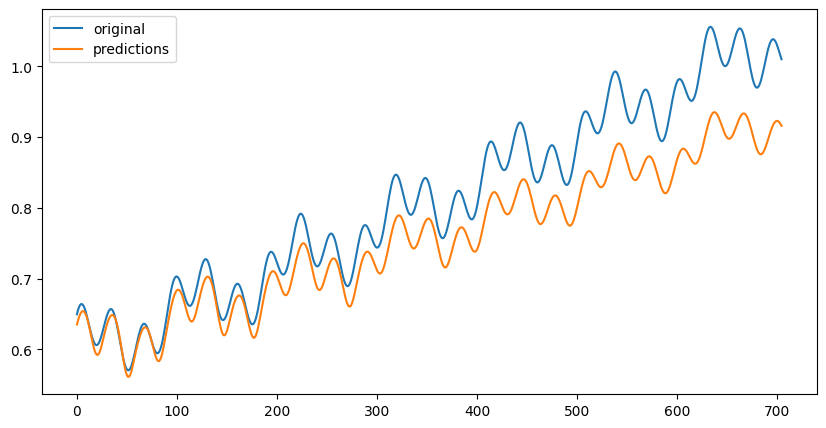

In [35]:
plt.figure(figsize=[10, 5])
plt.plot(test_targets, label='original')
plt.plot(test_preds.squeeze().cpu().numpy(), label='predictions')
plt.legend()
plt.show()

### Mini zadanie: Jak wyglądałyby predykcje w oparciu o poprzednie predykcje?

In [ ]:
with torch.no_grad():
    hidden, state = model.init_hidden(1)
    hidden, state = hidden.to(device), state.to(device) 
    hidden = (hidden,state)
    x_one = test_targets[0:1].unsqueeze(0).to(device)
    preds = []
    for i in range(len(test_targets)):
        # whole seq of len=150 time steps is passed, in short-term mem we iterate through all of 150 time steps in one input
        x_one, hidden = model(x_one.unsqueeze(0), hidden) 
        preds.append(x_one.item())

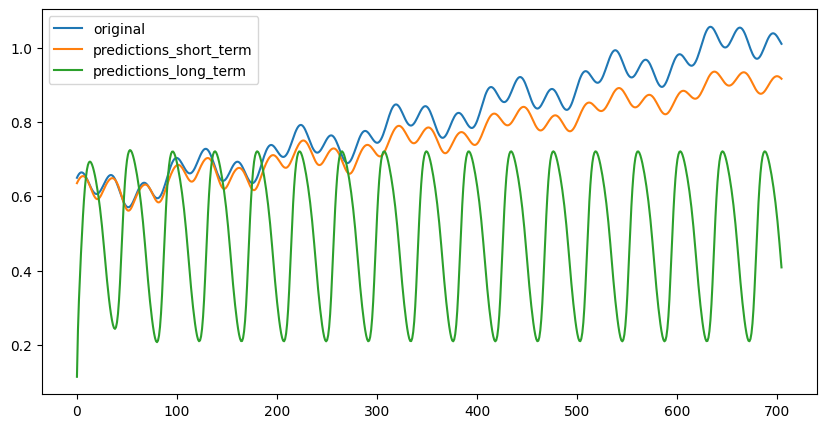

In [37]:
plt.figure(figsize=[10,5])
plt.plot(test_targets, label = 'original')
plt.plot(test_preds.squeeze().cpu().numpy(), label = 'predictions_short_term')
plt.plot(preds, label = 'predictions_long_term')
plt.legend()
plt.show()

# Predykcja Sequence to sequence

In [ ]:
stock_price = pd.read_csv("https://www.galera.ii.pw.edu.pl/~kdeja/data/all_stocks_5yr.csv") # cannot be read

In [ ]:
mastercard_stock = stock_price[stock_price.Name=="MA"].open.values
visa_stock = stock_price[stock_price.Name=="V"].open.values

In [ ]:
plt.figure(figsize=[10, 5])
plt.plot(mastercard_stock, label='mastercard')
plt.plot(visa_stock, label='visa')
plt.legend()
plt.show()

In [ ]:
m_min_value = mastercard_stock.min()
m_max_value = mastercard_stock.max()
v_min_value = visa_stock.min()
v_max_value = visa_stock.max()

In [ ]:
data_seq = []
data_targets = []
sequence_len = 50
for i in range(len(mastercard_stock) - sequence_len):
    data_seq.append(torch.from_numpy(mastercard_stock[i:i + sequence_len]))
    data_targets.append(torch.from_numpy(visa_stock[i:i + sequence_len]))
    
data = (torch.stack(data_seq).float() - m_min_value) / m_max_value
data_targets = (torch.stack(data_targets).float() - v_min_value) / v_max_value    

train_split = int(len(data) * 0.7)
train_set = torch.utils.data.TensorDataset(data[:train_split], data_targets[:train_split])
train_loader = DataLoader(train_set, batch_size=32, drop_last=True)
train_set = torch.utils.data.TensorDataset(data[:train_split], data_targets[:train_split])
train_loader = DataLoader(train_set, batch_size=32, drop_last=True)
test_data, test_targets = data[train_split:], data_targets[train_split:]

In [ ]:
sequence_length = 5
num_layers = 1
batch_size = 3
hidden_size = 2
projection_size = 1

lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=num_layers, proj_size=projection_size)
lstm_input = torch.randn(sequence_length, batch_size, 1)
hidden_0 = torch.randn(num_layers, batch_size, projection_size)
cell_state_0 = torch.randn(num_layers, batch_size, hidden_size)
output, (hn, cn) = lstm(lstm_input, (hidden_0, cell_state_0))

In [ ]:
output

In [ ]:
class LSTM_Seq_Regressor(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, out_size):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.proj_size = out_size
        self.lstm = nn.LSTM(input_size = input_size, hidden_size = hidden_size, num_layers = num_layers, proj_size=out_size)
        
    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.num_layers, batch_size, self.proj_size)
        state = torch.zeros(self.num_layers, batch_size, self.hidden_size)
        return hidden, state
    
    def forward(self, x, hidden):
        x = torch.transpose(x,0,1)
        all_outputs, hidden = self.lstm(x, hidden)
        all_outputs = torch.transpose(all_outputs,0,1)
        return all_outputs, hidden
    
model = LSTM_Seq_Regressor(1, 50, 2, 1).to(device)
model

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fun = nn.MSELoss()

# Training loop
for epoch in range(101):
    for x, targets in train_loader:
        x = x.to(device).unsqueeze(2)
        targets = targets.to(device)
        hidden, state = model.init_hidden(x.size(0))
        hidden, state = hidden.to(device), state.to(device) 
        preds, last_hidden = model(x, (hidden,state))
        preds = preds.squeeze(2)
        optimizer.zero_grad() 
        loss = loss_fun(preds, targets)
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

In [ ]:
with torch.no_grad():
    selected_test_targets = []
    preds = []
    for i in range(0, len(test_targets), sequence_len):
        hidden, state = model.init_hidden(1)
        hidden, state = hidden.to(device), state.to(device) 
        selected_test_targets.append(test_targets[i])
        pred, _ = model(test_data[i].to(device).unsqueeze(0).unsqueeze(2), (hidden, state))
        preds.append(pred.squeeze())

In [ ]:
plt.figure(figsize=[10, 5])
plt.plot(torch.cat(selected_test_targets).cpu().numpy(), label='original')
plt.plot(torch.cat(preds).cpu().numpy(), label='predicted')
plt.legend()
plt.show()

### Co się stało, skąd takie dziwne predykcje?

In [ ]:
with torch.no_grad():
    selected_test_targets = []
    preds = []
    hidden, state = model.init_hidden(1)
    hidden, state = hidden.to(device), state.to(device) 
    for i in range(0,len(test_targets),sequence_len):
        selected_test_targets.append(test_targets[i])
        pred, hidden_out = model(test_data[i].to(device).unsqueeze(0).unsqueeze(2), (hidden,state))
        hidden, state = hidden_out
        preds.append(pred.squeeze())

In [ ]:
plt.figure(figsize=[10,5])
plt.plot(torch.cat(selected_test_targets).cpu().numpy(), label = 'original')
plt.plot(torch.cat(preds).cpu().numpy(), label = 'predicted')
plt.legend()
plt.show()

# Klasyfikacja serii

In [40]:
libras = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/libras/movement_libras.data", header=None)

In [42]:
libras.head(n=10)

,0,1,2,3,4,5,6,7,8,9,...,81,82,83,84,85,86,87,88,89,90
0,0.79691,0.38194,0.79691,0.37731,0.79884,0.37731,0.79497,0.37731,0.77563,0.35417,...,0.51389,0.39845,0.42593,0.47389,0.36111,0.55899,0.31250,0.63830,0.29398,1
1,0.67892,0.27315,0.68085,0.27315,0.68085,0.27315,0.68085,0.27315,0.67892,0.26852,...,0.57407,0.17795,0.63657,0.17215,0.67361,0.17021,0.69213,0.17215,0.69213,1
2,0.72147,0.23611,0.72340,0.23611,0.72340,0.23611,0.72340,0.23611,0.72340,0.23611,...,0.30556,0.59768,0.25926,0.67118,0.25231,0.73501,0.26620,0.78143,0.27778,1
3,0.56480,0.32407,0.56286,0.32407,0.56093,0.32407,0.55899,0.32407,0.55899,0.32407,...,0.49074,0.26306,0.42361,0.33269,0.34722,0.41006,0.28009,0.49130,0.24306,1
4,0.67118,0.38426,0.67118,0.38657,0.67311,0.38657,0.67311,0.38426,0.67311,0.37963,...,0.76389,0.44101,0.64120,0.45068,0.54167,0.47776,0.44213,0.53191,0.34259,1
5,0.83366,0.35880,0.83752,0.37731,0.82979,0.38426,0.83172,0.37731,0.83172,0.41667,...,0.51157,0.55706,0.56019,0.64603,0.57870,0.74662,0.56713,0.83752,0.52546,1
6,0.71567,0.68056,0.71373,0.68056,0.70986,0.68981,0.71180,0.68287,0.71567,0.65741,...,0.61111,0.35397,0.57639,0.41006,0.52315,0.49130,0.48611,0.55899,0.48380,1
7,0.77563,0.60417,0.77563,0.60417,0.77950,0.59722,0.75629,0.53935,0.70793,0.44444,...,0.45833,0.54545,0.45370,0.61509,0.47685,0.66344,0.46759,0.71180,0.53472,1
8,0.77756,0.63426,0.77563,0.63426,0.77369,0.61806,0.75822,0.50694,0.71373,0.40509,...,0.46991,0.46422,0.43750,0.55899,0.44213,0.63250,0.46296,0.68085,0.48380,1
9,0.74468,0.58565,0.74468,0.59028,0.74662,0.58333,0.73501,0.55787,0.71180,0.47222,...,0.45833,0.56286,0.45602,0.62282,0.45370,0.66538,0.48148,0.71567,0.53935,1


In [ ]:
classes = libras[90].values
print(libras[90])   # filters column with title = 90 - it's last column, containing classes info
print(classes)
print(libras.values)
data = libras.values[:, :-1]    # all data ':', and all columns apart from last one with target ':-1'
data

0       1
1       1
2       1
3       1
4       1
       ..
355    15
356    15
357    15
358    15
359    15
Name: 90, Length: 360, dtype: int64
[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2  2
  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3  3
  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4
  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5
  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6
  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7  7
  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8  8
  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9  9
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11 11
 12 12 12 12 12 12 12 12 12 12 12 12 12 12 12 12 12

array([[0.79691, 0.38194, 0.79691, ..., 0.3125 , 0.6383 , 0.29398],
       [0.67892, 0.27315, 0.68085, ..., 0.69213, 0.17215, 0.69213],
       [0.72147, 0.23611, 0.7234 , ..., 0.2662 , 0.78143, 0.27778],
       ...,
       [0.61122, 0.75926, 0.61122, ..., 0.52083, 0.44487, 0.5162 ],
       [0.65957, 0.79167, 0.65764, ..., 0.52546, 0.54159, 0.52083],
       [0.64023, 0.71991, 0.64217, ..., 0.49537, 0.52031, 0.49306]],
      shape=(360, 90))

In [48]:
data = torch.from_numpy(data).float()
data_targets = torch.from_numpy(classes).long()

train_indices = rng.random(len(data)) > 0.3
test_indices = ~train_indices
train_set = torch.utils.data.TensorDataset(data[train_indices], data_targets[train_indices])
train_loader = DataLoader(train_set, batch_size=32)
test_data, test_targets = data[test_indices], data_targets[test_indices]

/var/folders/w2/3khqjd7d1m97phfx15lm1wyr0000gn/T/ipykernel_62046/2748985286.py:2: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  data_targets = torch.from_numpy(classes).long()


### Napisz klasyfikator

In [49]:
class LSTMRegressor(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, out_size, bidirectional = False):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        if bidirectional:
            self.bidirectional = 2
        else:
            self.bidirectional = 1
        self.lstm = nn.LSTM(input_size = input_size, hidden_size = hidden_size, num_layers = num_layers, bidirectional=bidirectional, dropout=0.4)
        self.fc = nn.Linear(hidden_size*90*self.bidirectional, out_size)
        
    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.num_layers*self.bidirectional , batch_size, self.hidden_size)
        state = torch.zeros(self.num_layers*self.bidirectional , batch_size, self.hidden_size)
        return hidden, state
    
    def forward(self, x, hidden):
        x = torch.transpose(x,0,1)
        all_outputs, hidden = self.lstm(x, hidden)
        all_outputs = torch.transpose(all_outputs,0,1)
        out = torch.flatten(all_outputs,1)
        x = self.fc(out)
        return x, hidden
    
model = LSTMRegressor(1,5,2,16).to(device)
model

LSTMRegressor(
  (lstm): LSTM(1, 5, num_layers=2, dropout=0.4)
  (fc): Linear(in_features=450, out_features=16, bias=True)
)

In [50]:
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
loss_fun = nn.CrossEntropyLoss()

# Training loop
for epoch in range(101):
    for x, targets in train_loader:
        x = x.to(device).unsqueeze(2)
#         x = x.unsqueeze(2)
        targets = targets.to(device)
        hidden, state = model.init_hidden(x.size(0))
        hidden, state = hidden.to(device), state.to(device) 
        preds, _ = model(x, (hidden,state))
        preds = preds.squeeze(1)
        optimizer.zero_grad() 
        loss = loss_fun(preds, targets)
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

Epoch: 0, loss: 3.15
Epoch: 10, loss: 1.91
Epoch: 20, loss: 1.74
Epoch: 30, loss: 0.849
Epoch: 40, loss: 0.491
Epoch: 50, loss: 0.435
Epoch: 60, loss: 0.398
Epoch: 70, loss: 0.359
Epoch: 80, loss: 0.318
Epoch: 90, loss: 0.277
Epoch: 100, loss: 0.234


In [51]:
with torch.no_grad():
    hidden, state = model.init_hidden(len(test_data))
    hidden, state = hidden.to(device), state.to(device) 
    preds,_ =  model(test_data.to(device).unsqueeze(2), (hidden,state))
print(f"Accuracy: {(torch.argmax(preds,1).cpu()==test_targets).sum().item()/len(test_targets):.3}")

Accuracy: 0.29


# Dane o różnej długości

In [52]:
from torch.utils.data import Dataset

class VariableLenDataset(Dataset):
    def __init__(self, in_data, target):
        self.data = [(x, y) for x, y in zip(in_data, target)]      

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        in_data, target = self.data[idx]
        return in_data, target

In [53]:
min_gen_val = 10
max_gen_val = 1001
samples = 1000
max_gen_len = 32

data = []
targets = []
max_val = -1
for _ in range(samples):
    seq_len = rng.integers(low=1, high=max_gen_len, size=1)
    data_in = rng.integers(low=min_gen_val, high=max_gen_val, size=seq_len)
    data_sum = np.array([data_in[:i + 1].sum() for i in range(len(data_in))])
    data.append(torch.from_numpy(data_in))
    targets.append(torch.from_numpy(data_sum))
    max_val = data_sum[-1] if data_sum[-1] > max_val else max_val

In [54]:
train_indices = int(len(data) * 0.7)
data = [(x / max_val).float() for x in data]
targets = [(x / max_val).float() for x in targets]
train_set = VariableLenDataset(data[:train_indices], targets[:train_indices])
test_set = VariableLenDataset(data[train_indices:], targets[train_indices:])

In [55]:
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

pad = 0

def pad_collate(batch, pad_value=0):
    xx, yy = zip(*batch)
    x_lens = [len(x) for x in xx]
    y_lens = [len(y) for y in yy]

    xx_pad = pad_sequence(xx, batch_first=True, padding_value=pad_value)
    yy_pad = pad_sequence(yy, batch_first=True, padding_value=pad_value)

    return xx_pad, yy_pad, x_lens, y_lens

In [56]:
train_loader = DataLoader(train_set, batch_size=50, shuffle=True, collate_fn=pad_collate)
test_loader = DataLoader(test_set, batch_size=50, shuffle=False, drop_last=False, collate_fn=pad_collate)

In [57]:
print(len(train_set[0][0]))
print(len(train_set[1][0]))

28
13


In [58]:
next(iter(train_loader))

(tensor([[0.0112, 0.0047, 0.0058,  ..., 0.0000, 0.0000, 0.0000],
         [0.0522, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0200, 0.0065, 0.0029,  ..., 0.0000, 0.0000, 0.0000],
         ...,
         [0.0463, 0.0130, 0.0484,  ..., 0.0000, 0.0000, 0.0000],
         [0.0061, 0.0032, 0.0028,  ..., 0.0435, 0.0346, 0.0226],
         [0.0203, 0.0267, 0.0483,  ..., 0.0000, 0.0000, 0.0000]]),
 tensor([[0.0112, 0.0159, 0.0217,  ..., 0.0000, 0.0000, 0.0000],
         [0.0522, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
         [0.0200, 0.0265, 0.0294,  ..., 0.0000, 0.0000, 0.0000],
         ...,
         [0.0463, 0.0593, 0.1077,  ..., 0.0000, 0.0000, 0.0000],
         [0.0061, 0.0093, 0.0121,  ..., 0.8100, 0.8446, 0.8673],
         [0.0203, 0.0470, 0.0953,  ..., 0.0000, 0.0000, 0.0000]]),
 [4,
  1,
  28,
  14,
  17,
  8,
  10,
  6,
  23,
  31,
  29,
  14,
  19,
  31,
  9,
  16,
  23,
  27,
  7,
  26,
  13,
  20,
  24,
  11,
  1,
  31,
  28,
  22,
  27,
  1,
  25,
  11,
  4,

In [61]:
class LSTM_Seq_Regressor(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, out_size):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.proj_size = out_size
        self.lstm = nn.LSTM(input_size = input_size, hidden_size = hidden_size, num_layers = num_layers, proj_size = out_size)
        
    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.num_layers, batch_size, self.proj_size)
        state = torch.zeros(self.num_layers, batch_size, self.hidden_size)
        return hidden, state
    
    def forward(self, x, hidden):
        # x = torch.transpose(x, 0, 1)
        all_outputs, hidden = self.lstm(x, hidden)
        # all_outputs = torch.transpose(all_outputs, 0, 1)
        return all_outputs, hidden
    
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LSTM_Seq_Regressor(1, 200, 1, 1).to(device)
model

LSTM_Seq_Regressor(
  (lstm): LSTM(1, 200, proj_size=1)
)

In [62]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fun = nn.MSELoss()

# Training loop
for epoch in range(101):
    for x, targets, x_len, target_len in train_loader:
        x = x.to(device).unsqueeze(2)
        targets = targets.to(device)
        hidden, state = model.init_hidden(x.size(0))
        hidden, state = hidden.to(device), state.to(device) 
        
        x = torch.transpose(x, 0, 1)
        preds, _ = model(x, (hidden, state))
        preds = torch.transpose(preds, 0, 1)
        
#         x_packed = pack_padded_sequence(x, x_len, batch_first=True, enforce_sorted=False)
#         preds_packed, _ = model(x_packed, (hidden, state))
#         preds, pred_len = pad_packed_sequence(preds_packed, batch_first=True, padding_value=pad)
        
        preds = preds.squeeze(2)
        optimizer.zero_grad()
        mask = targets != pad
        loss = loss_fun(preds[mask], targets[mask])
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {loss.item():.3}")

Epoch: 0, loss: 0.0458
Epoch: 10, loss: 0.0105
Epoch: 20, loss: 0.00122
Epoch: 30, loss: 0.00186
Epoch: 40, loss: 0.00188
Epoch: 50, loss: 0.000882
Epoch: 60, loss: 0.000481
Epoch: 70, loss: 0.000292
Epoch: 80, loss: 0.000119
Epoch: 90, loss: 9.91e-05
Epoch: 100, loss: 4.64e-05


In [63]:
with torch.no_grad():
    for x, targets, x_len, target_len in test_loader:
        x = x.to(device).unsqueeze(2)
        targets = targets.to(device)
        hidden, state = model.init_hidden(x.shape[0])
        hidden, state = hidden.to(device), state.to(device)

#         x = torch.transpose(x, 0, 1)        
#         preds, _ = model(x, (hidden, state))
#         preds = torch.transpose(preds, 0, 1)
        
        x_packed = pack_padded_sequence(x, x_len, batch_first=True, enforce_sorted=False)
        preds_packed, _ = model(x_packed, (hidden, state))
        preds, pred_len = pad_packed_sequence(preds_packed, batch_first=True, padding_value=pad)
        
        preds = preds.squeeze(2)
        mask_tgt = targets != pad
        print(targets)
        print(preds)
        print(torch.abs(preds[mask_tgt] - targets[mask_tgt]).mean())
        print()

tensor([[0.0390, 0.0568, 0.0889,  ..., 0.0000, 0.0000, 0.0000],
        [0.0122, 0.0377, 0.0884,  ..., 0.0000, 0.0000, 0.0000],
        [0.0493, 0.0578, 0.0943,  ..., 0.0000, 0.0000, 0.0000],
        ...,
        [0.0308, 0.0579, 0.0932,  ..., 0.0000, 0.0000, 0.0000],
        [0.0149, 0.0165, 0.0508,  ..., 0.0000, 0.0000, 0.0000],
        [0.0504, 0.0844, 0.0893,  ..., 0.0000, 0.0000, 0.0000]])
tensor([[0.0368, 0.0554, 0.0881,  ..., 0.0000, 0.0000, 0.0000],
        [0.0124, 0.0388, 0.0892,  ..., 0.0000, 0.0000, 0.0000],
        [0.0463, 0.0559, 0.0928,  ..., 0.0000, 0.0000, 0.0000],
        ...,
        [0.0293, 0.0567, 0.0924,  ..., 0.0000, 0.0000, 0.0000],
        [0.0148, 0.0191, 0.0547,  ..., 0.0000, 0.0000, 0.0000],
        [0.0472, 0.0805, 0.0871,  ..., 0.0000, 0.0000, 0.0000]])
tensor(0.0067)

tensor([[0.0053, 0.0350, 0.0863,  ..., 0.0000, 0.0000, 0.0000],
        [0.0183, 0.0517, 0.0810,  ..., 0.0000, 0.0000, 0.0000],
        [0.0278, 0.0544, 0.0843,  ..., 0.0000, 0.0000, 0.000